In [1]:
%%capture captured_output
%%time


In [2]:
import os
import warnings
warnings.filterwarnings('ignore')


In [3]:
root_dir = '.'
root_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar"

In [4]:
def check_sym_path(dir):
    sym_path = os.path.join(dir, 'test_file')
    if not os.path.lexists(sym_path):
        try:
            os.symlink(os.path.join(os.sep, 'tmp'), sym_path)
            os.remove(sym_path)
            print("Passed -> Symlink test")
            return True

        except OSError as e:
            print(f"File error ->\n{e}")
            return False
    else:
        print("File exists -> file removed.")

        os.remove(sym_path)

In [5]:
import tarfile
from pathlib import Path
import httpx
import skillsnetwork

In [6]:
async def root_download(url, path, dir):
    if not os.path.lexists(path):
        try:
            async with httpx.AsyncClient() as c:
                response = await c.get(url)
                response.raise_for_status()

                with open(path, 'wb') as f:
                    f.write(response.content)

        except OSError as e:
            print(f"{e}")

    else:
        print("file exists")

    with tarfile.open(path, 'r:*') as t:
        t.extractall(dir, filter='data')

In [7]:
if check_sym_path(root_dir):
    try:
        await skillsnetwork.prepare(root_url, root_dir, overwrite=True)

    except:
        file_name = Path(root_url).name
        tar_file = os.path.join(root_dir, file_name)
        await root_download(root_url, tar_file, root_dir)

Passed -> Symlink test


  0%|          | 0/6003 [00:00<?, ?it/s]

Saved to '.'


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torch.nn.functional as F

In [ ]:
import keras
import tensorflow as tf
from keras.models import Sequential, Model 
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from keras.layers import GlobalAveragePooling2D
from keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.initializers import HeUniform
from keras.callbacks import ModelCheckpoint
import numpy as np


In [10]:
keras_torch_dir = "."

keras_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/U-uPeyCyOQYh0GrZPGsqoQ/ai-capstone-keras-best-model-model.keras"
keras_name = "ai-capstone-keras-best-model-model_downloaded.keras"
keras_path = os.path.join(keras_torch_dir, keras_name)

torch_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/8J2QEyQqD8x9zjrlnv6N7g/ai-capstone-pytorch-best-model-20250713.pth"
torch_name = "ai_capstone_pytorch_best_model_state_dict_downloaded.pth"
torch_path = os.path.join(keras_torch_dir, torch_name)



In [11]:
async def keras_torch_download(url, path):
    if not os.path.lexists(path):
        print("Initiate download...")
        try:
            async with httpx.AsyncClient() as client:
                response = await client.get(url, follow_redirects=True)
                response.raise_for_status()
                print("Download complete.")
                with open(path, 'wb') as f:
                    f.write(response.content)
        except Exception as e:
            print("Error --> \n{e}")

    else:
        print("File exists.")
        
await keras_torch_download(keras_url, keras_path)
await keras_torch_download(torch_url, torch_path)



File exists.
File exists.


In [12]:
full_data_path = os.path.join(root_dir, 'images_dataSAT')

img_h, img_w = (64, 64)
n_channels = 3
batch_size = 128
num_classes = 2
class_labels = sorted(os.listdir(full_data_path))

print(class_labels)

['class_0_non_agri', 'class_1_agri']


In [13]:
keras_image_generator = ImageDataGenerator(
    rescale=1./255
)

keras_prediction_generator = keras_image_generator.flow_from_directory(
    full_data_path,
    target_size = (img_h, img_w),
    batch_size = batch_size,
    shuffle=False,
    class_mode = 'binary',
    classes = class_labels
)



Found 6000 images belonging to 2 classes.


In [14]:
keras_model = tf.keras.models.load_model(keras_path)

In [15]:
steps = int(np.ceil(keras_prediction_generator.samples / keras_prediction_generator.batch_size))

batch_size = int(keras_prediction_generator.batch_size)

In [16]:
from tqdm import tqdm

all_preds_keras = []
all_probs_keras = []
all_labels_keras = []

for step_idx, step in enumerate(tqdm(range(steps), desc='Steps')):
    images, labels = next(keras_prediction_generator)
    preds = keras_model.predict(images, verbose=0)
    all_probs_keras.extend(preds)
    preds = (preds > 0.5).astype(int).flatten()
    all_preds_keras.extend(preds)
    all_labels_keras.extend(labels)

Steps: 100%|██████████| 47/47 [00:03<00:00, 12.93it/s]


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize

In [18]:
def keras_torch_metrics(y_true, y_pred, y_prob, class_labels):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "Log Loss": log_loss(y_true, y_prob),
        "Confusion Matrix": confusion_matrix(y_true, y_pred),
        "Classification Report": classification_report(y_true, y_pred, target_names=class_labels, digits=4),
        "Class Labels": class_labels
    }
    return metrics

In [19]:
def print_metrics(y_true, y_pred, y_prob, class_labels, model_name):
    metrics = keras_torch_metrics(y_true, y_pred, y_prob, class_labels)
    print(f"Evaluation metrics for the \033[1m{model_name}\033[0m")
    print(f"Accuracy: {'':<1}{metrics['Accuracy']:.4f}")
    print(f"ROC-AUC: {'':<2}{metrics['ROC AUC']:.4f}")
    print(f"Loss: {'':>5}{metrics['Log Loss']:.4f}")
    print(f"Classification Report:\n\n {metrics['Classification Report']}")
    print("Confusion Matrix")
    disp = ConfusionMatrixDisplay(confusion_matrix = metrics['Confusion Matrix'],
                                  display_labels = metrics['Class Labels'])

    disp.plot()
    plt.title(model_name)
    plt.show()


Evaluation metrics for the keras model
Accuracy:  0.9925
ROC-AUC:   1.0000
Loss:      0.0247
Classification Report:

                   precision    recall  f1-score   support

class_0_non_agri     0.9852    1.0000    0.9926      3000
    class_1_agri     1.0000    0.9850    0.9924      3000

        accuracy                         0.9925      6000
       macro avg     0.9926    0.9925    0.9925      6000
    weighted avg     0.9926    0.9925    0.9925      6000

Confusion Matrix


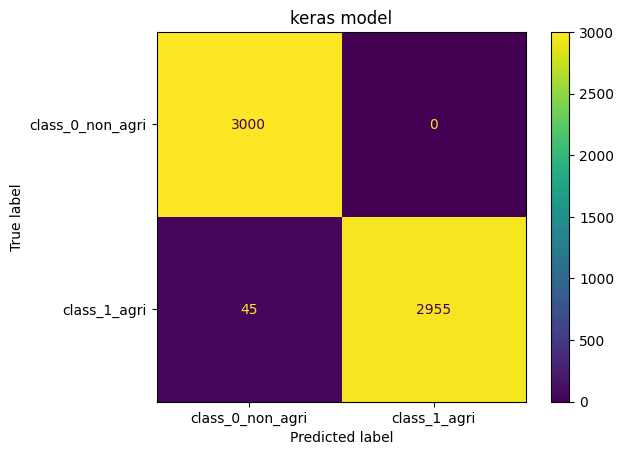

In [20]:
print_metrics(y_true = all_labels_keras,
              y_pred = all_preds_keras,
              y_prob = all_probs_keras,
              class_labels = class_labels,
              model_name = "keras model")

In [21]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'


In [22]:
torch_train_transform = transforms.Compose([
    transforms.Resize((img_h, img_w)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [23]:
torch_dataset = datasets.ImageFolder(
    full_data_path,
    transform = torch_train_transform
)

torch_test_loader = DataLoader(
    torch_dataset,
    batch_size = batch_size,
    shuffle = False
)

In [24]:
torch_model = nn.Sequential(
    nn.Conv2d(3, 32, 5, padding=2), nn.ReLU(),
    nn.MaxPool2d(2), nn.BatchNorm2d(32),
    nn.Conv2d(32, 64, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(64),
    nn.Conv2d(64, 128, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(128),
    nn.Conv2d(128, 256, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(256),
    nn.Conv2d(256, 512, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(512),
    nn.Conv2d(512, 1024, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(1024),
    nn.AdaptiveAvgPool2d(1), nn.Flatten(),
    nn.Linear(1024, 2048), nn.ReLU(), nn.BatchNorm1d(2048), nn.Dropout(0.4),
    nn.Linear(2048, num_classes)
).to(device)

In [25]:
torch_model.load_state_dict(torch.load(torch_path))

<All keys matched successfully>

In [26]:
all_preds_torch = []
all_probs_torch = []
all_labels_torch = []

torch_model.eval()
with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(tqdm(torch_test_loader, desc='Steps')):
        images = images.to(device)
        outputs = torch_model(images)
        preds = torch.argmax(outputs, dim=1)
        probs = F.softmax(outputs, dim=1)[:, 1]
        all_preds_torch.extend(preds.cpu().numpy().flatten())
        all_probs_torch.extend(probs.cpu().numpy())
        all_labels_torch.extend(labels.numpy())

Steps: 100%|██████████| 47/47 [00:01<00:00, 39.95it/s]


Evaluation metrics for the Torch Model
Accuracy:  0.9988
ROC-AUC:   1.0000
Loss:      0.0024
Classification Report:

                   precision    recall  f1-score   support

class_0_non_agri     0.9993    0.9983    0.9988      3000
    class_1_agri     0.9983    0.9993    0.9988      3000

        accuracy                         0.9988      6000
       macro avg     0.9988    0.9988    0.9988      6000
    weighted avg     0.9988    0.9988    0.9988      6000

Confusion Matrix


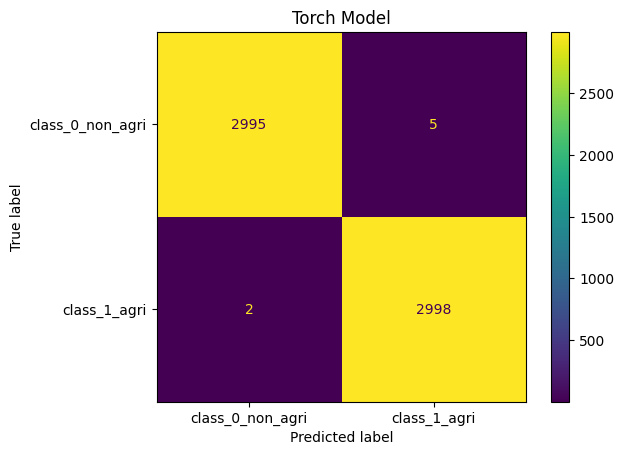

In [27]:
print_metrics(
    y_true = all_labels_torch,
    y_pred = all_preds_torch,
    y_prob = all_probs_torch,
    class_labels = class_labels,
    model_name = "Torch Model"
)

In [ ]:

def plot_roc(y_true, y_prob, model_name):
    n_classes = y_prob.shape[1] if y_prob.ndim > 1 else 1
    if n_classes == 1:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc = roc_auc_score(y_true, y_prob)
        plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.2f})')
    else:
        y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
            auc = roc_auc_score(y_true_bin[:, i], y_prob[:, i])
            plt.plot(fpr, tpr, label=f'{model_name} class {i} (AUC = {auc:.2f})')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()


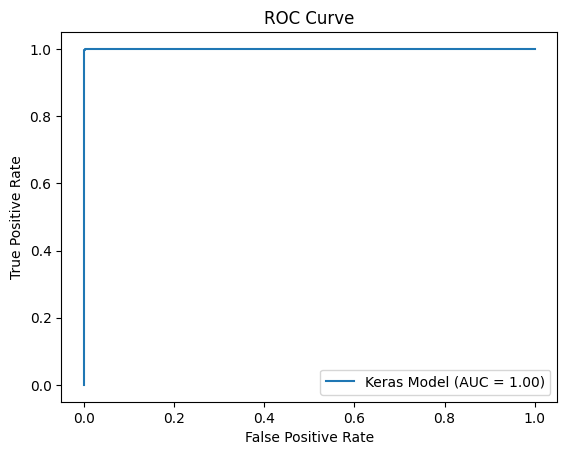

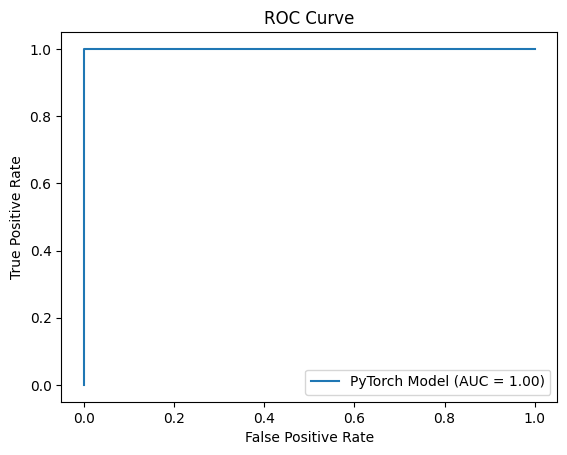

In [31]:
plot_roc(np.array(all_labels_keras), np.array(all_probs_keras), "Keras Model")
plt.show()
plot_roc(np.array(all_labels_torch), np.array(all_probs_torch), "PyTorch Model")
plt.show()

In [36]:
# get the Keras model performance metrics
metrics_keras = keras_torch_metrics(all_labels_keras, all_preds_keras, all_probs_keras, class_labels)

# get the PyTorch model performance metrics
metrics_torch = keras_torch_metrics(all_labels_torch, all_preds_torch, all_probs_torch, class_labels)


# Display the comparison of metrics
print("{:<18} {:<15} {:<15}".format('\033[1m'+ 'Metric' + '\033[0m',
                                    'Keras Model', 
                                    'PyTorch Model'))

mertics_list = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

for k in mertics_list:
    print("{:<18} {:<15.4f} {:<15.4f}".format('\033[1m'+k+'\033[0m',
                                              metrics_keras[k],
                                              metrics_torch[k]))

Metric     Keras Model     PyTorch Model  
Accuracy   0.9925          0.9988         
Precision  1.0000          0.9983         
Recall     0.9850          0.9993         
F1         0.9924          0.9988         
ROC AUC    1.0000          1.0000         
